# Lean Convolutional $\beta$-VAE for SMLM Background Synthesis

This notebook trains a **lean Convolutional $\beta$-Variational Autoencoder** (~95k parameters) on normalised $64 \times 64$ background patches $\hat{B}(y, x)$ ($\mu = 0, \sigma = 1$) generated by our disk-cached `noise_maps/` augmentation pipeline ([05_simulator.ipynb](file:///Users/rohan/Documents/projects/mphys/localisation_workflow/05_simulator.ipynb)).

### Design & Generalisation Safeguards
1. **Movie-Level Train / Validation Hold-Out:**
   - **Training Set (3 independent recordings, 33 noise maps):** `LowDensity_SealG_F3` (`+ _1`), `LowDensity_SealA_F3`, and `HighDensity_SealG_F8` (`+ _1`).
   - **Held-Out Validation Set (1 completely unseen recording, 12 noise maps):** `HighDensity_SealA_F8` (`+ _1`). Because every patch is standardised to $\mu = 0, \sigma = 1$ before entering the VAE, validation loss directly measures whether the VAE generalises to unseen 2D spatial illumination/autofluorescence topologies.
2. **Artifact-Free Smooth Decoder:**
   - Uses **`Upsample(mode='bilinear') + Conv2d(padding_mode='replicate')`** instead of `ConvTranspose2d` *(Odena et al., 2016)* to eliminate checkerboard artifacts and zero-padding edge steps.
3. **Pixel-Averaged $\beta$-ELBO + Spatial Gradient Loss with KL Annealing:**
   $$\mathcal{L} = \operatorname{MSE}(\hat{B}, \hat{B}_{\mathrm{rec}}) + \lambda_{\mathrm{grad}}\,\|\nabla\hat{B} - \nabla\hat{B}_{\mathrm{rec}}\|_1 + \beta(t)\,\frac{D_{\mathrm{KL}}(q_\phi(\mathbf{z}\mid\hat{B})\,\|\,\mathcal{N}(\mathbf{0}, \mathbf{I}_d))}{P^2}$$
   with latent dimension $d = 16$, linear KL warmup, and a nearest-neighbour novelty check to verify the decoder synthesises genuinely new backgrounds rather than memorising training patches.

### References
- **Kingma, D. P., & Welling, M.** (2014). Auto-Encoding Variational Bayes. *ICLR*.
- **Higgins, I., et al.** (2017). $\beta$-VAE: Learning Basic Visual Concepts with a Constrained Variational Framework. *ICLR*.
- **Odena, A., Dumoulin, V., & Olah, C.** (2016). Deconvolution and Checkerboard Artifacts. *Distill*.


In [1]:
import json
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from scipy.ndimage import rotate, affine_transform

torch.manual_seed(42)
np.random.seed(42)
# device = torch.device('cpu')
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')

project = Path('/Users/rohan/Documents/projects/mphys')
workflow_dir = project / 'localisation_workflow'
noise_maps_dir = workflow_dir / 'vae_background' / 'noise_maps'
manifest = json.loads((noise_maps_dir / 'manifest.json').read_text())

# Movie-level Train / Validation split: hold out HighDensity_SealA_F8 (+ _1) completely
VAL_IDS = {'HighDensity_SealA_F8', 'HighDensity_SealA_F8_1'}
train_manifest = [m for m in manifest if m['dataset_id'] not in VAL_IDS]
val_manifest = [m for m in manifest if m['dataset_id'] in VAL_IDS]

print(f'Train noise maps: {len(train_manifest)} (from {len(set(m["dataset_id"] for m in train_manifest))} files)')
print(f'Val   noise maps: {len(val_manifest)} (held-out unseen recording: HighDensity_SealA_F8 + _1)')

Train noise maps: 33 (from 5 files)
Val   noise maps: 12 (held-out unseen recording: HighDensity_SealA_F8 + _1)


In [2]:
class BackgroundPatchAugmentor:
    def __init__(self, manifest_list, maps_dir=noise_maps_dir, patch_size=64,
                 stretch_range=(0.75, 1.35), shear_deg_range=(-15.0, 15.0), max_convex_k=2):
        self.manifest = manifest_list
        self.maps_dir = Path(maps_dir)
        self.patch_size = patch_size
        self.stretch_range = stretch_range
        self.shear_deg_range = shear_deg_range
        self.max_convex_k = max_convex_k

    def sample_single_warped(self, P, rng):
        item = self.manifest[int(rng.integers(0, len(self.manifest)))]
        bg_mmap = np.load(self.maps_dir / item['filename'], mmap_mode='r')
        H, W = bg_mmap.shape
        P_src = int(np.ceil(P * 1.80))
        if P_src % 2 != P % 2:
            P_src += 1
        half_s = P_src // 2
        cy = int(rng.integers(half_s, H - half_s + 1))
        cx = int(rng.integers(half_s, W - half_s + 1))
        work = np.array(bg_mmap[cy - half_s : cy + half_s, cx - half_s : cx + half_s], dtype=np.float32, copy=True)

        # Stage 1: Coin-flip reflection + continuous rotation
        if rng.random() < 0.5:
            work = np.fliplr(work)
        theta = float(rng.uniform(0.0, 360.0))
        work = rotate(work, angle=theta, reshape=False, order=3, mode='nearest')

        # Stage 2: Anisotropic affine stretch + shear
        s_y, s_x = float(rng.uniform(*self.stretch_range)), float(rng.uniform(*self.stretch_range))
        psi_y, psi_x = float(rng.uniform(*self.shear_deg_range)), float(rng.uniform(*self.shear_deg_range))
        A_fwd = np.array([[s_y, np.tan(np.deg2rad(psi_x))], [np.tan(np.deg2rad(psi_y)), s_x]], dtype=np.float64)
        A_inv = np.linalg.inv(A_fwd)
        c_vec = np.array([half_s, half_s], dtype=np.float64)
        work = affine_transform(work, matrix=A_inv, offset=c_vec - A_inv @ c_vec, order=3, mode='nearest')
        patch = work[half_s - P // 2 : half_s + P // 2, half_s - P // 2 : half_s + P // 2].copy()
        return patch.astype(np.float32)

    def sample_normalised(self, rng, k_mix=None):
        P = self.patch_size
        if k_mix is None:
            k_mix = int(rng.integers(1, self.max_convex_k + 1))
        if k_mix == 1:
            p = self.sample_single_warped(P, rng)
            return ((p - p.mean()) / (p.std() + 1e-6)).astype(np.float32)
        weights = rng.dirichlet(np.ones(k_mix, dtype=np.float64)).astype(np.float32)
        norms = []
        for _ in range(k_mix):
            p = self.sample_single_warped(P, rng)
            norms.append((p - p.mean()) / (p.std() + 1e-6))
        mix = sum(w * n for w, n in zip(weights, norms))
        return (mix / (mix.std() + 1e-6)).astype(np.float32)


PATCH_SIZE = 64
N_TRAIN = 3600
N_VAL = 500

train_aug = BackgroundPatchAugmentor(train_manifest, patch_size=PATCH_SIZE, max_convex_k=2)
val_aug = BackgroundPatchAugmentor(val_manifest, patch_size=PATCH_SIZE, max_convex_k=1)  # Pure unseen FOV patches for val

rng_tr = np.random.default_rng(100)
rng_va = np.random.default_rng(999)

X_train = torch.from_numpy(np.stack([train_aug.sample_normalised(rng_tr) for _ in range(N_TRAIN)])).unsqueeze(1)
X_val = torch.from_numpy(np.stack([val_aug.sample_normalised(rng_va) for _ in range(N_VAL)])).unsqueeze(1)

train_loader = DataLoader(TensorDataset(X_train), batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val), batch_size=64, shuffle=False)

print(f'X_train shape: {tuple(X_train.shape)} | X_val shape: {tuple(X_val.shape)}')
print(f'Train empirical mean/std: ({X_train.mean():.3f}, {X_train.std():.3f}) | Val: ({X_val.mean():.3f}, {X_val.std():.3f})')

X_train shape: (3600, 1, 64, 64) | X_val shape: (500, 1, 64, 64)
Train empirical mean/std: (-0.000, 1.000) | Val: (0.000, 1.000)


## 2. Lean Convolutional $\beta$-VAE Architecture (`1 -> 16 -> 32 -> 64` at $8 \times 8$, $d = 32$)

We keep the channel widths compact (`16 -> 32 -> 64`) and **stop spatial downsampling at $8 \times 8$** (3 stride-2 layers instead of 4), so each bottleneck spatial cell spans $8 \times 8\text{ px}$ rather than $16 \times 16\text{ px}$. In the decoder, we use replicate padding, bilinear upsampling, and **extra $3 \times 3$ refinement convolutions at the $32 \times 32$ and $64 \times 64$ scales** to preserve sharper mid-frequency pocket curvature without checkerboard artifacts.

### Tuning $\beta_{\max}$ Relative to the Pixel-Averaged Reconstruction MSE
In our initial $d = 16$ run ($\text{KL} \approx 36\text{ nats}$, $P^2 = 64^2 = 4096$), the pixel-normalised KL term was $36 / 4096 \approx 0.009$. Multiplying by `BETA_MAX = 2.0` gave a KL penalty of $\sim 0.018$, which is fairly strong relative to the reconstruction MSE ($\sim 0.052$). Lowering `BETA_MAX` (e.g., from `2.0` $\rightarrow$ `1.0` or `0.5`) relaxes that information bottleneck so the VAE can preserve sharper mid-frequency pocket structure while still regularising the latent space toward $\mathcal{N}(\mathbf{0}, \mathbf{I}_d)$.

In [3]:
class SmoothBgBetaVAE(nn.Module):
    def __init__(self, latent_dim: int = 32):
        super().__init__()
        self.latent_dim = latent_dim

        # Encoder: (B, 1, 64, 64) -> (B, 64, 8, 8) (3 stride-2 stages + 8x8 refinement)
        self.enc = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1, padding_mode='replicate'),
            nn.GroupNorm(4, 16),
            nn.SiLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1, padding_mode='replicate'),
            nn.GroupNorm(8, 32),
            nn.SiLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1, padding_mode='replicate'),
            nn.GroupNorm(8, 64),
            nn.SiLU(),
            nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=1, padding_mode='replicate'),
            nn.GroupNorm(8, 64),
            nn.SiLU(),
        )
        self.fc_mu = nn.Linear(64 * 8 * 8, latent_dim)
        self.fc_logvar = nn.Linear(64 * 8 * 8, latent_dim)

        # Decoder: (B, d) -> (B, 64, 8, 8) -> (B, 1, 64, 64) with 3x3 refinement convs at 32x32 & 64x64
        self.fc_dec = nn.Linear(latent_dim, 64 * 8 * 8)
        self.dec = nn.Sequential(
            # 8x8 -> 16x16
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(64, 32, kernel_size=3, padding=1, padding_mode='replicate'),
            nn.GroupNorm(8, 32),
            nn.SiLU(),

            # 16x16 -> 32x32 + extra 3x3 refinement conv
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(32, 16, kernel_size=3, padding=1, padding_mode='replicate'),
            nn.GroupNorm(4, 16),
            nn.SiLU(),
            nn.Conv2d(16, 16, kernel_size=3, padding=1, padding_mode='replicate'),
            nn.GroupNorm(4, 16),
            nn.SiLU(),

            # 32x32 -> 64x64 + extra 3x3 refinement conv + linear output head
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(16, 16, kernel_size=3, padding=1, padding_mode='replicate'),
            nn.GroupNorm(4, 16),
            nn.SiLU(),
            nn.Conv2d(16, 16, kernel_size=3, padding=1, padding_mode='replicate'),
            nn.SiLU(),
            nn.Conv2d(16, 1, kernel_size=3, padding=1, padding_mode='replicate'),
        )

    def encode(self, x):
        h = self.enc(x).flatten(1)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterise(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h = F.silu(self.fc_dec(z)).view(-1, 64, 8, 8)
        return self.dec(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterise(mu, logvar)
        return self.decode(z), mu, logvar


def spatial_grad_loss(x_rec, x):
    dy_rec = x_rec[:, :, 1:, :] - x_rec[:, :, :-1, :]
    dy_gt = x[:, :, 1:, :] - x[:, :, :-1, :]
    dx_rec = x_rec[:, :, :, 1:] - x_rec[:, :, :, :-1]
    dx_gt = x[:, :, :, 1:] - x[:, :, :, :-1]
    return 0.5 * (F.l1_loss(dy_rec, dy_gt) + F.l1_loss(dx_rec, dx_gt))


def compute_vae_loss(x_rec, x, mu, logvar, beta, lambda_grad=0.15):
    mse = F.mse_loss(x_rec, x, reduction='mean')
    grad = spatial_grad_loss(x_rec, x)
    # Sum KL over latent dims, averaged over batch, then normalised by P*P so beta ~ O(1)
    kl_nats = -0.5 * torch.sum(1.0 + logvar - mu.pow(2) - logvar.exp(), dim=1).mean()
    kl_scaled = kl_nats / (x.shape[-2] * x.shape[-1])
    total = mse + lambda_grad * grad + beta * kl_scaled
    return total, mse, grad, kl_nats


LATENT_DIM = 32
vae = SmoothBgBetaVAE(latent_dim=LATENT_DIM).to(device)
n_params = sum(p.numel() for p in vae.parameters() if p.requires_grad)
print(f'SmoothBgBetaVAE total trainable parameters: {n_params:,}')

FORCE_RETRAIN = True  # Set True to retrain from scratch and watch live epoch progress
EPOCHS = 35
BETA_MAX = 1.25
WARMUP_EPOCHS = 8
optimizer = torch.optim.AdamW(vae.parameters(), lr=1.5e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-4)

history = {k: [] for k in ['tr_tot', 'tr_mse', 'tr_grad', 'tr_kl', 'va_tot', 'va_mse', 'va_grad', 'va_kl', 'beta']}
best_val_mse = float('inf')
vae_dir = workflow_dir / 'vae_background'
vae_dir.mkdir(parents=True, exist_ok=True)
ckpt_path = vae_dir / 'bg_vae_64x64.pt'

if FORCE_RETRAIN or not ckpt_path.exists():
    for epoch in range(1, EPOCHS + 1):
        beta_t = BETA_MAX * min(1.0, epoch / WARMUP_EPOCHS)
        vae.train()
        tr_sums = np.zeros(4, dtype=np.float64)
        n_tr_b = 0
        for (xb,) in train_loader:
            xb = xb.to(device)
            optimizer.zero_grad()
            x_rec, mu, logvar = vae(xb)
            tot, mse, grad, kl = compute_vae_loss(x_rec, xb, mu, logvar, beta=beta_t)
            tot.backward()
            optimizer.step()
            tr_sums += [tot.item(), mse.item(), grad.item(), kl.item()]
            n_tr_b += 1
        scheduler.step()

        vae.eval()
        va_sums = np.zeros(4, dtype=np.float64)
        n_va_b = 0
        with torch.no_grad():
            for (xb,) in val_loader:
                xb = xb.to(device)
                x_rec, mu, logvar = vae(xb)
                tot, mse, grad, kl = compute_vae_loss(x_rec, xb, mu, logvar, beta=beta_t)
                va_sums += [tot.item(), mse.item(), grad.item(), kl.item()]
                n_va_b += 1

        tr_m = tr_sums / n_tr_b
        va_m = va_sums / n_va_b
        for i, name in enumerate(['tot', 'mse', 'grad', 'kl']):
            history[f'tr_{name}'].append(tr_m[i])
            history[f'va_{name}'].append(va_m[i])
        history['beta'].append(beta_t)

        if epoch >= WARMUP_EPOCHS and va_m[1] < best_val_mse:
            best_val_mse = va_m[1]
            torch.save({'model_state': vae.state_dict(), 'latent_dim': LATENT_DIM, 'patch_size': PATCH_SIZE}, ckpt_path)

        if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
            print(
                f'Epoch {epoch:>2}/{EPOCHS} (beta={beta_t:.2f}) | '
                f'Train MSE={tr_m[1]:.4f}, KL={tr_m[3]:.2f} | '
                f'Val MSE={va_m[1]:.4f}, Grad={va_m[2]:.4f}, KL={va_m[3]:.2f}'
            )

    print(f'Saved best post-warmup checkpoint to {ckpt_path.relative_to(project)} (Val MSE={best_val_mse:.4f})')
else:
    print(f"Loaded existing checkpoint from {ckpt_path.relative_to(project)} (set FORCE_RETRAIN = True to retrain).")


SmoothBgBetaVAE total trainable parameters: 488,305
Epoch  1/35 (beta=0.16) | Train MSE=0.2133, KL=153.36 | Val MSE=0.1169, Grad=0.0500, KL=119.00
Epoch  5/35 (beta=0.78) | Train MSE=0.0436, KL=73.96 | Val MSE=0.0566, Grad=0.0430, KL=77.75
Epoch 10/35 (beta=1.25) | Train MSE=0.0357, KL=65.59 | Val MSE=0.0468, Grad=0.0415, KL=67.61
Epoch 15/35 (beta=1.25) | Train MSE=0.0331, KL=64.12 | Val MSE=0.0431, Grad=0.0409, KL=70.34
Epoch 20/35 (beta=1.25) | Train MSE=0.0307, KL=62.99 | Val MSE=0.0415, Grad=0.0407, KL=67.66
Epoch 25/35 (beta=1.25) | Train MSE=0.0302, KL=61.89 | Val MSE=0.0413, Grad=0.0408, KL=64.13
Epoch 30/35 (beta=1.25) | Train MSE=0.0294, KL=61.65 | Val MSE=0.0405, Grad=0.0407, KL=65.25
Epoch 35/35 (beta=1.25) | Train MSE=0.0291, KL=61.11 | Val MSE=0.0405, Grad=0.0408, KL=64.75
Saved best post-warmup checkpoint to localisation_workflow/vae_background/bg_vae_64x64.pt (Val MSE=0.0404)


## 3. Training vs. Held-Out Validation Curves & Generalisation Diagnostics

Below we inspect:
1. **Train vs. Held-Out Validation Loss Curves** (Total $\beta$-ELBO, MSE reconstruction, Spatial Gradient L1, and KL divergence in nats) to confirm there is no train/val divergence.
2. **Unseen Validation Reconstructions (`HighDensity_SealA_F8`):** Real held-out patches vs. VAE reconstructions vs. residual errors.
3. **Prior Sampling ($\mathbf{z} \sim \mathcal{N}(\mathbf{0}, \mathbf{I}_{32})$) & Nearest-Neighbour Novelty Check:** Decodes 5 fresh samples from the Gaussian prior and compares each against its closest patch in `X_train` to prove the VAE synthesises genuinely new 2D background topologies rather than memorising training examples.


*(Once trained, the frozen decoder is loaded in [05_simulator.ipynb](file:///Users/rohan/Documents/projects/mphys/localisation_workflow/05_simulator.ipynb) Section 5 to drive DECODE 3D spline PSF simulations.)*


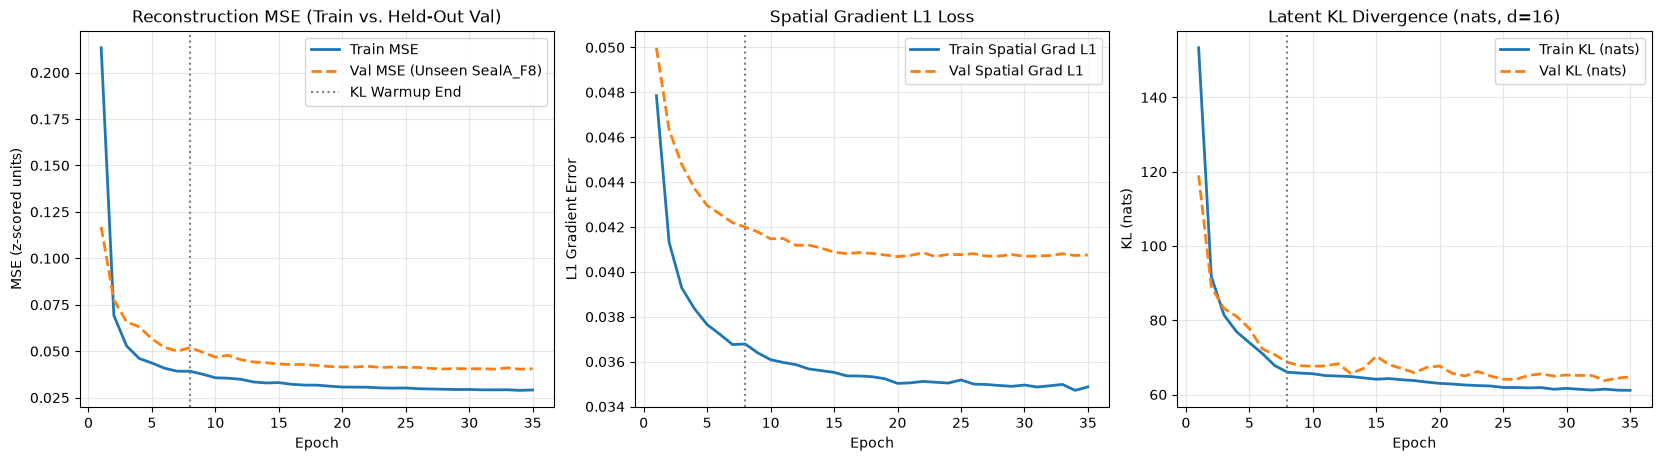

In [4]:
if len(history["tr_mse"]) > 0:
    # Reload best checkpoint
    ckpt = torch.load(ckpt_path, map_location=device)
    vae.load_state_dict(ckpt['model_state'])
    vae.eval()

    # --- Figure 1: Train vs. Held-Out Validation Curves ---
    fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.5), constrained_layout=True)
    ep = np.arange(1, EPOCHS + 1)

    axes[0].plot(ep, history['tr_mse'], label='Train MSE', linewidth=2)
    axes[0].plot(ep, history['va_mse'], label='Val MSE (Unseen SealA_F8)', linewidth=2, linestyle='--')
    axes[0].axvline(WARMUP_EPOCHS, color='gray', linestyle=':', label='KL Warmup End')
    axes[0].set_title('Reconstruction MSE (Train vs. Held-Out Val)')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('MSE (z-scored units)')
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    axes[1].plot(ep, history['tr_grad'], label='Train Spatial Grad L1', linewidth=2)
    axes[1].plot(ep, history['va_grad'], label='Val Spatial Grad L1', linewidth=2, linestyle='--')
    axes[1].axvline(WARMUP_EPOCHS, color='gray', linestyle=':')
    axes[1].set_title('Spatial Gradient L1 Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('L1 Gradient Error')
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()

    axes[2].plot(ep, history['tr_kl'], label='Train KL (nats)', linewidth=2)
    axes[2].plot(ep, history['va_kl'], label='Val KL (nats)', linewidth=2, linestyle='--')
    axes[2].axvline(WARMUP_EPOCHS, color='gray', linestyle=':')
    axes[2].set_title('Latent KL Divergence (nats, d=16)')
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylabel('KL (nats)')
    axes[2].grid(True, alpha=0.3)
    axes[2].legend()
    plt.show()
    fig1_ref = fig
else:
    print("Skipped loss-curve plot (loaded pre-trained checkpoint without retraining).")


Active latent dimensions (KL > 0.1 nats): 32 / 32
Per-dim KL (nats): [2.22 2.09 1.9  2.17 1.46 1.54 2.39 2.05 1.4  1.67 1.24 3.07 1.59 1.66
 1.4  1.97 2.43 1.51 1.72 2.16 1.48 1.76 1.96 2.12 2.53 2.28 2.85 2.32
 1.88 2.88 2.4  3.04]


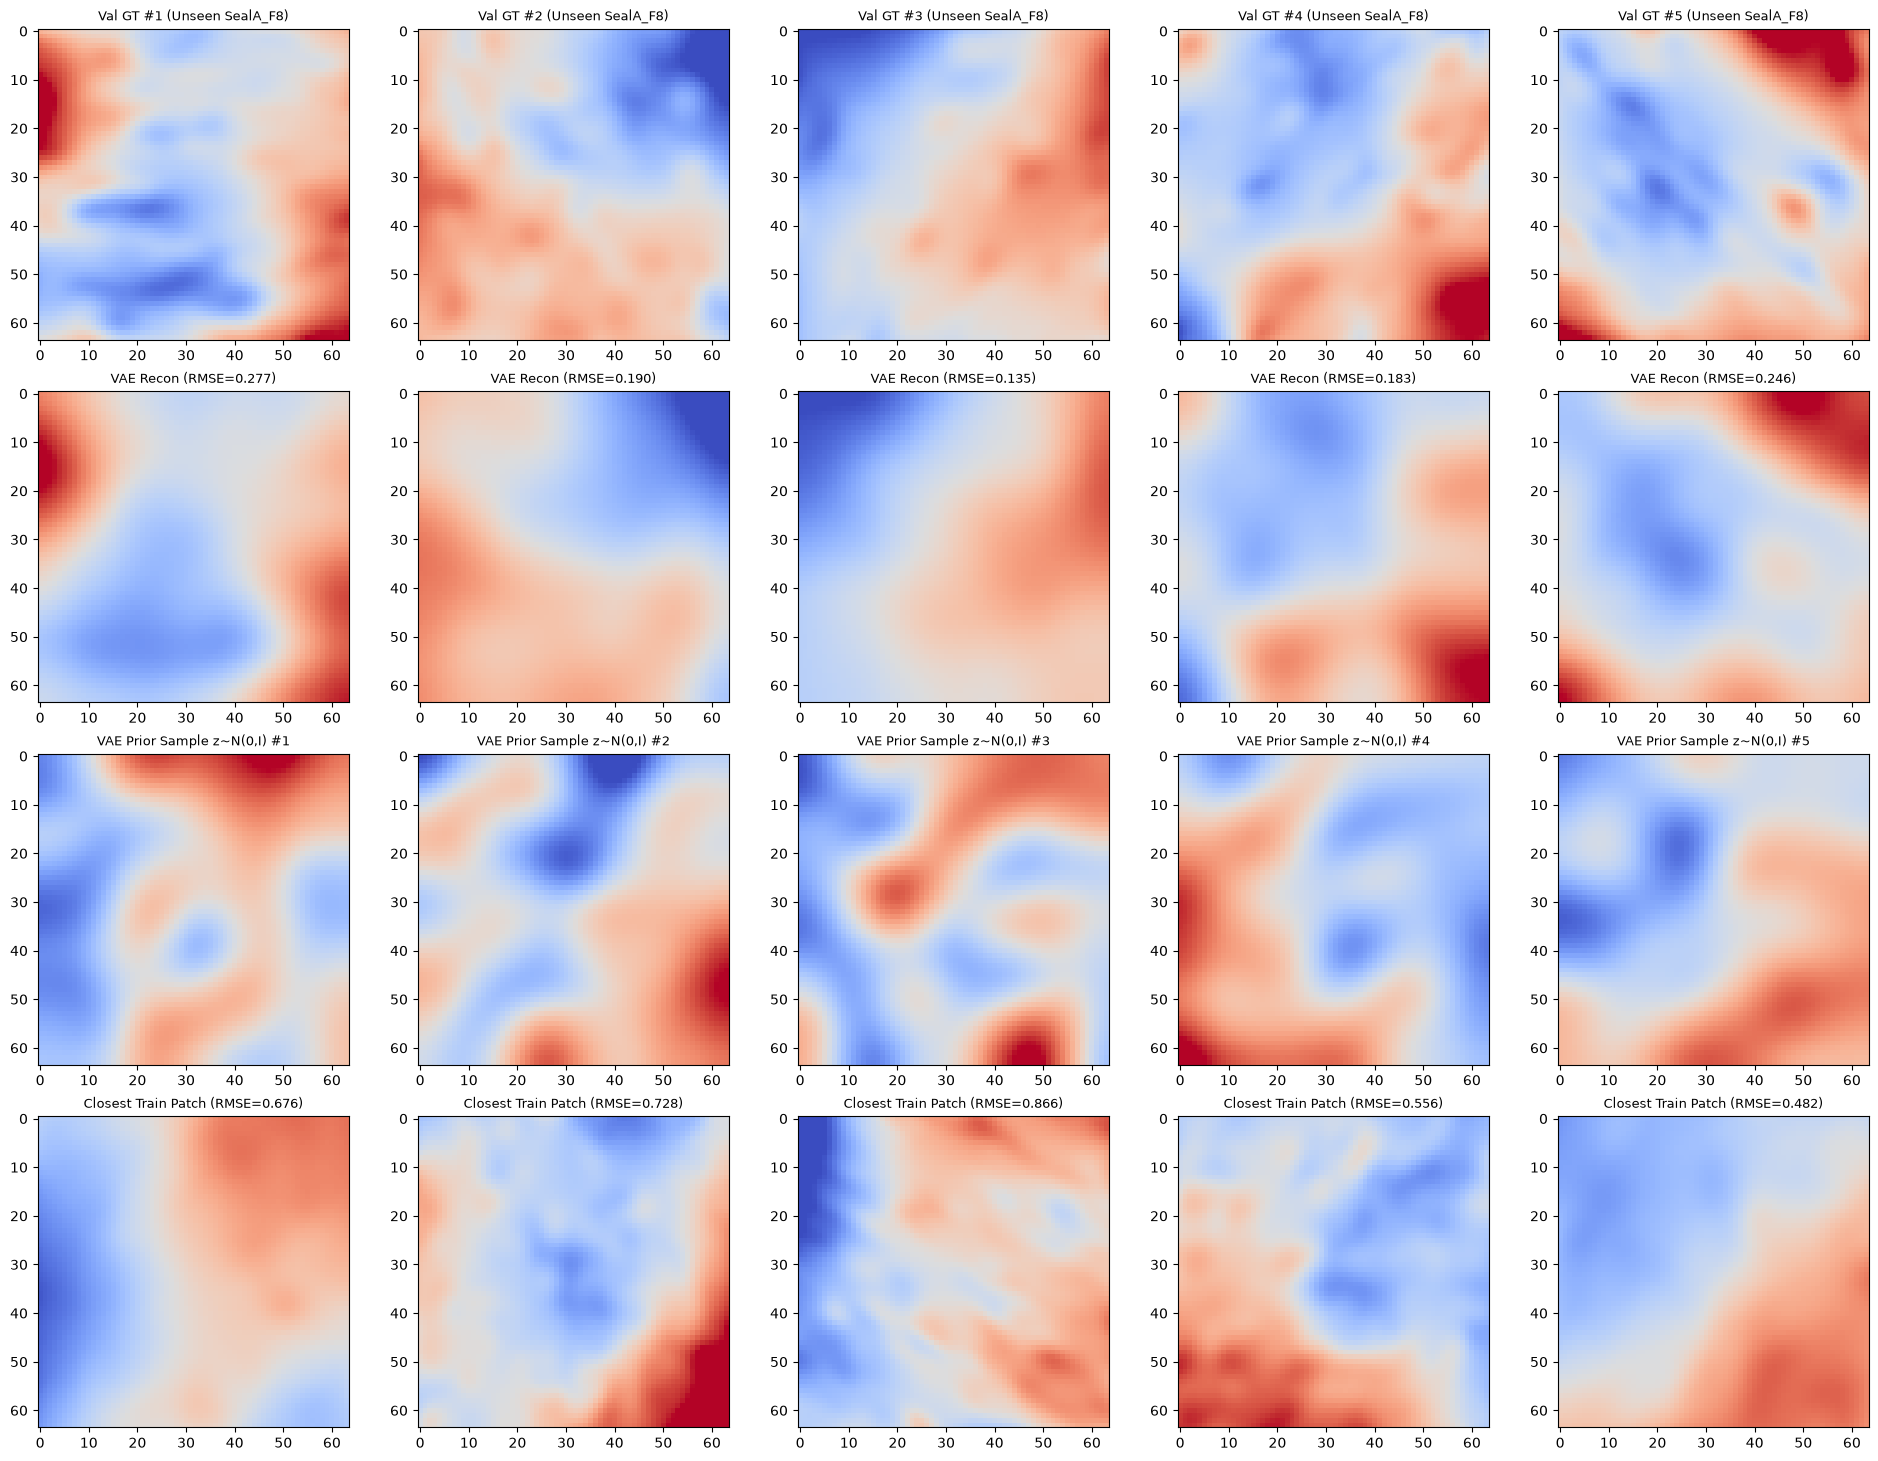

In [5]:
# --- Figure 2: Held-Out Validation Reconstructions + Prior Sampling + Nearest-Neighbour Novelty ---
with torch.no_grad():
    val_samples = X_val[:5].to(device)
    val_rec, val_mu, val_logvar = vae(val_samples)
    # Also compute per-dimension KL across full validation set to check active latent units
    all_mu, all_lv = [], []
    for (xb,) in val_loader:
        m, lv = vae.encode(xb.to(device))
        all_mu.append(m); all_lv.append(lv)
    all_mu = torch.cat(all_mu, dim=0)
    all_lv = torch.cat(all_lv, dim=0)
    kl_per_dim = (-0.5 * (1 + all_lv - all_mu.pow(2) - all_lv.exp())).mean(dim=0).cpu().numpy()
    active_dims = int((kl_per_dim > 0.1).sum())

    # Sample 5 fresh latent vectors from N(0, I_16)
    torch.manual_seed(77)
    z_prior = torch.randn(5, vae.latent_dim, device=device)
    prior_gen = vae.decode(z_prior)
    # Re-standardise each generated shape to exact mu=0, std=1
    prior_norm = (prior_gen - prior_gen.mean(dim=(2, 3), keepdim=True)) / (prior_gen.std(dim=(2, 3), keepdim=True) + 1e-6)

    # Nearest-neighbour search in X_train for each generated sample
    X_tr_flat = X_train.view(N_TRAIN, -1)
    gen_flat = prior_norm.view(5, -1).cpu()
    dists = torch.cdist(gen_flat, X_tr_flat, p=2) / np.sqrt(PATCH_SIZE * PATCH_SIZE)
    nn_rmse, nn_idx = dists.min(dim=1)

print(f'Active latent dimensions (KL > 0.1 nats): {active_dims} / {vae.latent_dim}')
print('Per-dim KL (nats):', np.round(kl_per_dim, 2))

fig, axes = plt.subplots(4, 5, figsize=(19, 14.5), constrained_layout=True)
for col in range(5):
    gt = val_samples[col, 0].cpu().numpy()
    rc = val_rec[col, 0].cpu().numpy()
    err = gt - rc
    rmse_v = float(np.sqrt(np.mean(err**2)))

    axes[0, col].imshow(gt, cmap='coolwarm', vmin=-2.5, vmax=2.5)
    axes[0, col].set_title(f'Val GT #{col+1} (Unseen SealA_F8)', fontsize=9.5)

    axes[1, col].imshow(rc, cmap='coolwarm', vmin=-2.5, vmax=2.5)
    axes[1, col].set_title(f'VAE Recon (RMSE={rmse_v:.3f})', fontsize=9.5)

    gen_img = prior_norm[col, 0].cpu().numpy()
    nn_img = X_train[int(nn_idx[col]), 0].numpy()
    axes[2, col].imshow(gen_img, cmap='coolwarm', vmin=-2.5, vmax=2.5)
    axes[2, col].set_title(f'VAE Prior Sample z~N(0,I) #{col+1}', fontsize=9.5)

    axes[3, col].imshow(nn_img, cmap='coolwarm', vmin=-2.5, vmax=2.5)
    axes[3, col].set_title(f'Closest Train Patch (RMSE={nn_rmse[col]:.3f})', fontsize=9.5)

plt.show()
